In [2]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
import astropy.coordinates as coord
from astropy.wcs import WCS
import astropy.units as u
from astroquery.vizier import Vizier
from scipy.optimize import curve_fit
from scipy.spatial.distance import cdist
from scipy.ndimage import label
from glob import glob
import cmastro
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pprint

plt.rcParams['image.origin'] = 'lower'

Useful functions for working with .fits files

In [3]:
def read_file(filename):
    image = fits.open("{f}".format(f=filename))[0].data.astype(int)
    return image

def header(filename):
    header = fits.open("{f}".format(f=filename))[0].header
    return header

def view(image, title, c = 'gray'):
    fig = plt.figure(figsize=(24, 12))
    vmin, vmax = ZScaleInterval().get_limits(image)
    plt.imshow(image, vmin=vmin, vmax=vmax, origin='lower', cmap=c)
    plt.title(title)
    plt.colorbar()
    plt.show()

def get_and_sort_files(folder, extension = 'fts'):
    # Get all .fts files
    files = [y for x in os.walk(folder) for y in glob(os.path.join(x[0], '*.' + extension))]

    # Pick out types of images and sort
    asteroid_files = [f for f in files if "26Proserpina-" in f]
    ast_headers = [header(f) for f in asteroid_files]
    flat_files = [f for f in files if "Flat" in f]
    dark_files = [f for f in files if "Dark" in f]
    bias_files = [f for f in files if "Bias" in f]
    asteroid_files.sort()
    flat_files.sort() 
    dark_files.sort() 
    bias_files.sort()
    return asteroid_files, ast_headers, flat_files, dark_files, bias_files   

**1. Get images categorized by date and type**

In [4]:
# 4 obs nights, 3 astroid images each
folder = "26Proserpina/"
observations = ["20120119", "20120120", "20120122", "20120125"]

# Images paths for each obs night
asteroid1, headers1, flats1, darks1, biases1 = get_and_sort_files(folder + observations[0])
asteroid2, headers2, flats2, darks2, biases2 = get_and_sort_files(folder + observations[1])
asteroid3, headers3, flats3, darks3, biases3 = get_and_sort_files(folder + observations[2])
asteroid4, headers4, flats4, darks4, biases4 = get_and_sort_files(folder + observations[3])

**2. Clean the images**

View all exposures and temperatures

In [5]:
flats = flats1 + flats2 + flats3 + flats4
darks = darks1 + darks2 + darks3 + darks4
biases = biases1 + biases2 + biases3 + biases4
astroids = asteroid1 + asteroid2 + asteroid3 + asteroid4
headers = headers1 + headers2 + headers3 + headers4
for asteroid in astroids:
    exp = header(asteroid)["EXPOSURE"]
    date = header(asteroid)["DATE-OBS"]
    temp = header(asteroid)["CCD-TEMP"]
    print("ASTEROID {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for flat in flats:
    exp = header(flat)["EXPOSURE"]
    date = header(flat)["DATE-OBS"]
    temp = header(flat)["CCD-TEMP"]
    print("FLAT {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for dark in darks:
    exp = header(dark)["EXPOSURE"]
    date = header(dark)["DATE-OBS"]
    temp = header(dark)["CCD-TEMP"]
    print("DARK {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for bias in biases:
    exp = header(bias)["EXPOSURE"]
    date = header(bias)["DATE-OBS"]
    temp = header(bias)["CCD-TEMP"]
    print("BIAS {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))

ASTEROID 2012-01-20T07:27:54 - Exposure: 60.0s, Temp: -25.218294750000005
ASTEROID 2012-01-20T07:29:21 - Exposure: 60.0s, Temp: -25.108281000000005
ASTEROID 2012-01-20T07:30:48 - Exposure: 60.0s, Temp: -25.117710750000004
ASTEROID 2012-01-21T07:39:37 - Exposure: 60.0s, Temp: -25.114567500000007
ASTEROID 2012-01-21T07:41:03 - Exposure: 60.0s, Temp: -25.023413250000004
ASTEROID 2012-01-21T07:42:29 - Exposure: 60.0s, Temp: -25.06113225
ASTEROID 2012-01-23T08:35:52 - Exposure: 60.0s, Temp: -25.183719
ASTEROID 2012-01-23T08:37:18 - Exposure: 60.0s, Temp: -25.14914325
ASTEROID 2012-01-23T08:38:44 - Exposure: 60.0s, Temp: -25.139713500000006
ASTEROID 2012-01-26T05:05:05 - Exposure: 60.0s, Temp: -25.123997250000002
ASTEROID 2012-01-26T05:06:19 - Exposure: 60.0s, Temp: -25.070562000000002
ASTEROID 2012-01-26T05:07:33 - Exposure: 60.0s, Temp: -25.136570250000005
-----------------------------
FLAT 2012-01-20T00:44:14 - Exposure: 1.75s, Temp: -4.702302
FLAT 2012-01-20T00:44:28 - Exposure: 2.07s, T

For the first, night the temperature controller was apparently off when taking the darks, so master dark will be from only 2/3 nights.

In [6]:
flats = [flat for flat in flats if header(flat)["CCD-Temp"] < -15]

We only want 60s darks to match our sky images. Now to create median images to use for cleaning

In [7]:
darks60 = [dark for dark in darks if np.abs(header(dark)["EXPOSURE"] - 60) <= 1]
print(darks60)

['26Proserpina/20120119/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120125/Calibration/Dark

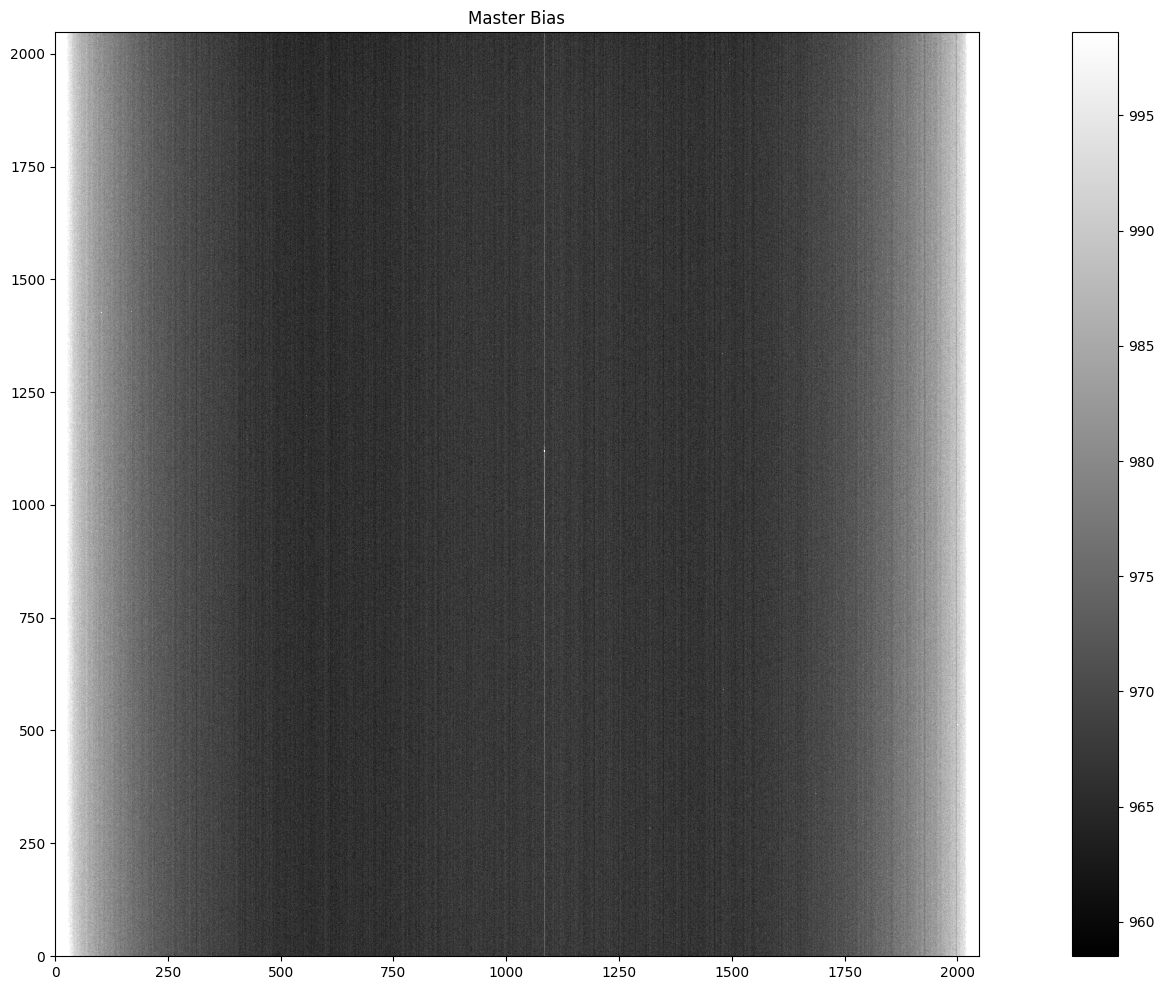

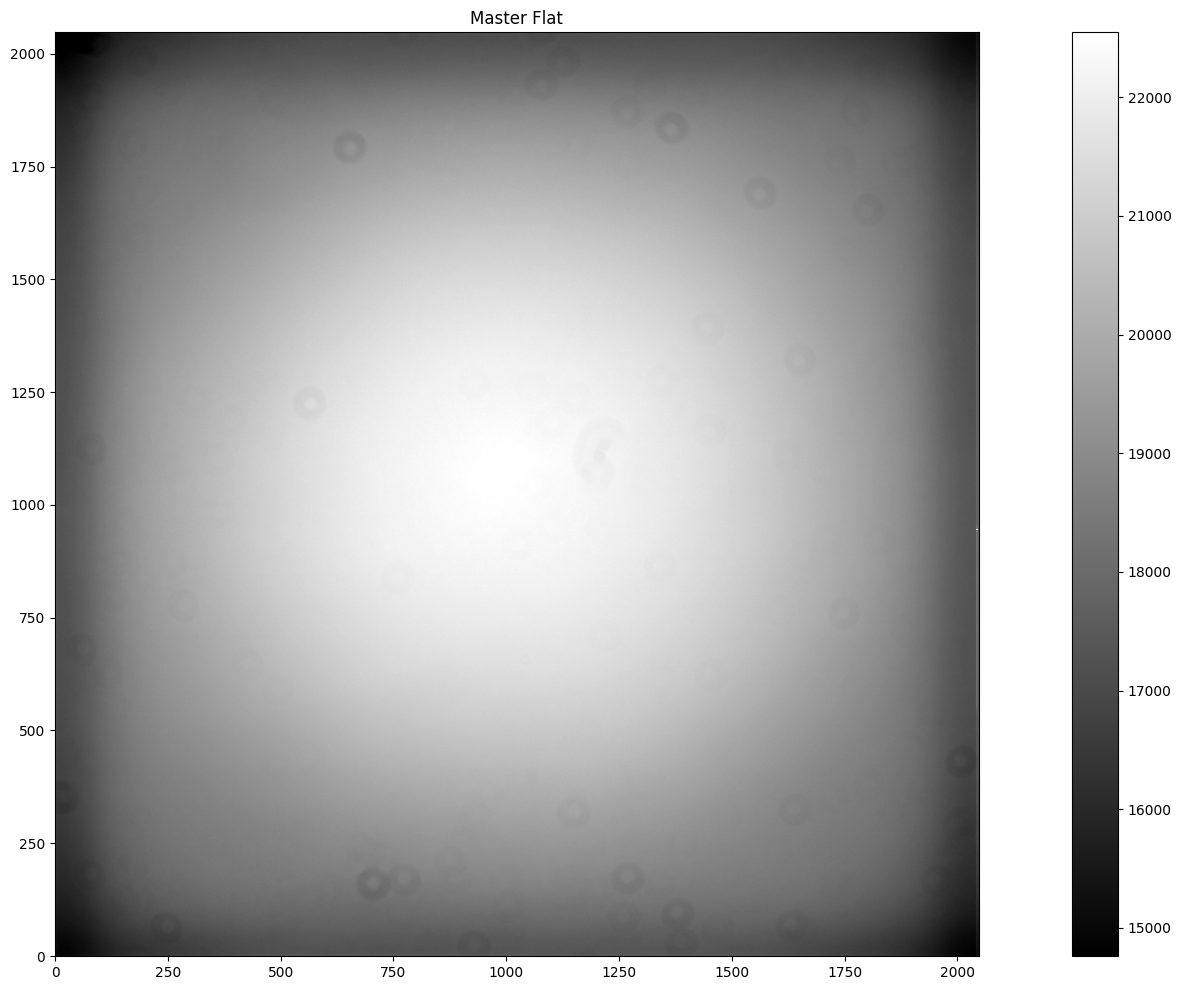

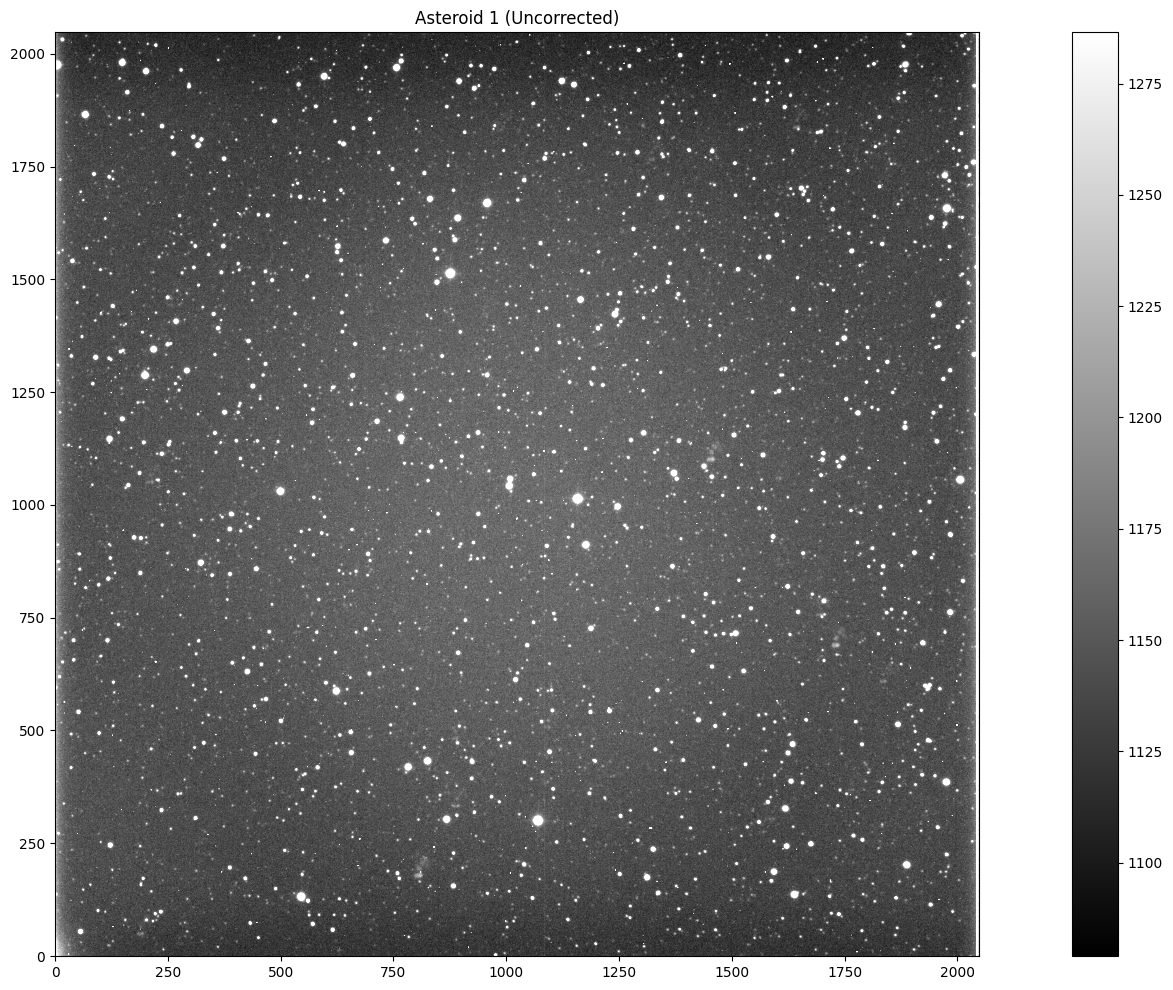

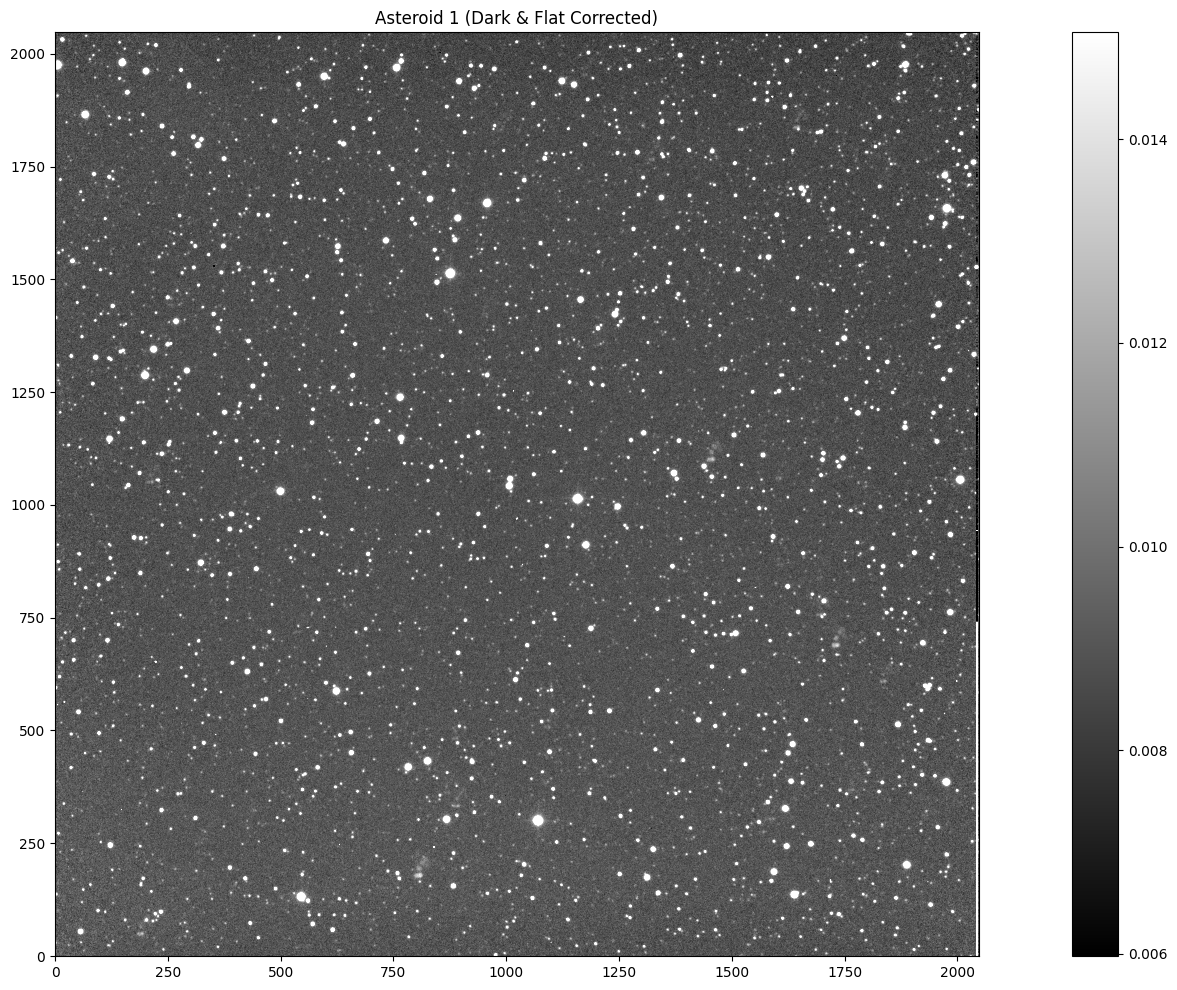

In [8]:
# Numpy arrays of images
all_astroid_np = np.array([read_file(f) for f in astroids])
all_biases_np = np.array([read_file(f) for f in biases])
all_dark60_np = np.array([read_file(f) for f in darks60])
all_flat_np = np.array([read_file(f) for f in flats])

# Flip science images
all_astroid_np = [all_astroid_np[::-1,::-1] for all_astroid_np in all_astroid_np]
# Median combine darks
master_dark = np.median(all_dark60_np, axis=0)
master_flat = np.median(all_flat_np, axis=0)
master_bias = np.median(all_biases_np, axis=0)

view(master_bias, "Master Bias")
view(master_flat, "Master Flat")

science_imgs = ((all_astroid_np - master_dark) / (master_flat))

view(all_astroid_np[0], "Asteroid 1 (Uncorrected)")
view(science_imgs[0], "Asteroid 1 (Dark & Flat Corrected)")

In [9]:

# for i, image in enumerate(science_imgs):
#     view(image, "Science Image Numer {i}".format(i=i), 'cma:lacerta')

**Crossmatching Stars**

Centroid Finding Algorithm

In [79]:
def star_gaussian(stars, image, threshold, plot=False, size=10):    
    centroids_x_coords = []
    centroids_y_coords = []
    initial_cen_x = []
    initial_cen_y = []
    
    failed_fittings = 0
    size = size
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()

    for i in range(len(stars[0])):
        box = image[int(stars[0][i])-size:int(stars[0][i])+size, int(stars[1][i])-size:int(stars[1][i])+size]
        
        # Create coordinate matrices and flatten them for fitting
        xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
        xx_flat = xx.ravel()
        yy_flat = yy.ravel()

        # Use centroid equation for initial guess
        y = np.sum(xx * box) / np.sum(box) 
        x = np.sum(yy * box) / np.sum(box) 

        # Fit Gaussian
        if len(yy_flat) != 0:            
            try:
                initial_guess = (1,x,y,size/2,size/2,0)
                popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess, nan_policy='omit')
                
                # get new centroid
                centroid_x, centroid_y = popt[1], popt[2]
                
                # put the coords back in the original context of the image
                x = stars[0][i] - size + x
                y = stars[1][i] - size + y
                centroid_x = stars[0][i] - size + centroid_x
                centroid_y = stars[1][i] - size + centroid_y
                
                print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                print(f"Inital Centroid: {x}, {y}")
                print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                
                # add centroids to list of coords
                initial_cen_x.append(x)
                initial_cen_y.append(y)
                centroids_x_coords.append(centroid_x)
                centroids_y_coords.append(centroid_y)
                
            except RuntimeError:
                failed_fittings += 1
                
    print(f"Couldn't fit {failed_fittings} stars")
    return centroids_x_coords, centroids_y_coords, initial_cen_x, initial_cen_y

        

Applying to all stars

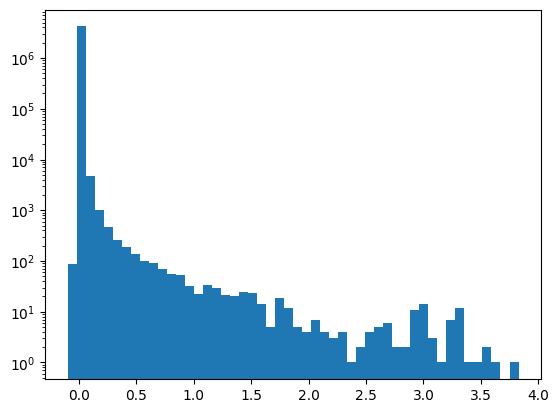

In [11]:
plt.hist(science_imgs[0].flatten(), bins=50)
plt.yscale('log')

Found 635 stars
Initial Coordinate: 2043, 369
Inital Centroid: 2042.4467419096263, 368.51996069609515
Gaussian Centroid: 2040.4096270711889, 369.41023052898674
Initial Coordinate: 1198, 27
Inital Centroid: 1197.578324397133, 26.53206308557769
Gaussian Centroid: 1201.3364486705786, 24.974795922136877
Initial Coordinate: 450, 40
Inital Centroid: 449.4583623805565, 39.483812904029634
Gaussian Centroid: 447.89119880172007, 39.696408496973675
Initial Coordinate: 56, 53
Inital Centroid: 58.05470547338516, 51.31349949957786
Gaussian Centroid: 59.12551116474221, 50.9515058896869
Initial Coordinate: 614, 57
Inital Centroid: 613.5208873218814, 56.46648154984508
Gaussian Centroid: 612.2219729081856, 54.56764360265689
Initial Coordinate: 1788, 55
Inital Centroid: 1787.4921031065435, 54.56444641104051
Gaussian Centroid: 1784.0144848129125, 58.25563143773191
Initial Coordinate: 1463, 57
Inital Centroid: 1462.4543405357979, 56.517871941525485
Gaussian Centroid: 1464.9249933165024, 57.50373575548298
I

/tmp/ipykernel_141076/3658684309.py:24: RuntimeWarning: invalid value encountered in scalar divide
  x = np.sum(xx * box) / np.sum(box)
/tmp/ipykernel_141076/3658684309.py:25: RuntimeWarning: invalid value encountered in scalar divide
  y = np.sum(yy * box) / np.sum(box)
/tmp/ipykernel_141076/3658684309.py:31: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess, nan_policy='omit')


Initial Coordinate: 1418, 169
Inital Centroid: 1417.5574578745702, 168.68635008050103
Gaussian Centroid: 1418.2102954809104, 179.34388122688713
Initial Coordinate: 195, 171
Inital Centroid: 194.44414743297818, 170.4974060889383
Gaussian Centroid: 190.52254464148737, 171.60782036334285
Initial Coordinate: 421, 171
Inital Centroid: 420.44018335949005, 170.52788759219513
Gaussian Centroid: 422.52445350130455, 168.6742863645622
Initial Coordinate: 1033, 178
Inital Centroid: 1032.4975944530672, 177.48481920576845
Gaussian Centroid: 1034.982766278516, 174.18910797840383
Initial Coordinate: 1250, 181
Inital Centroid: 1249.4767091568924, 180.52698286408668
Gaussian Centroid: 1248.8796009487567, -363.156966035595
Initial Coordinate: 547, 180
Inital Centroid: 546.4476511773745, 179.486360676035
Gaussian Centroid: 543.9895881942291, 181.25897760916664
Initial Coordinate: 758, 183
Inital Centroid: 757.4937870944914, 182.52270902886565
Gaussian Centroid: 757.4381064191002, 182.4915765650862
Initial

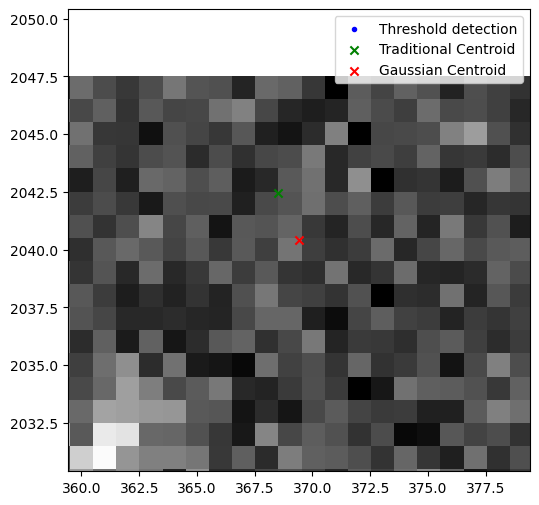

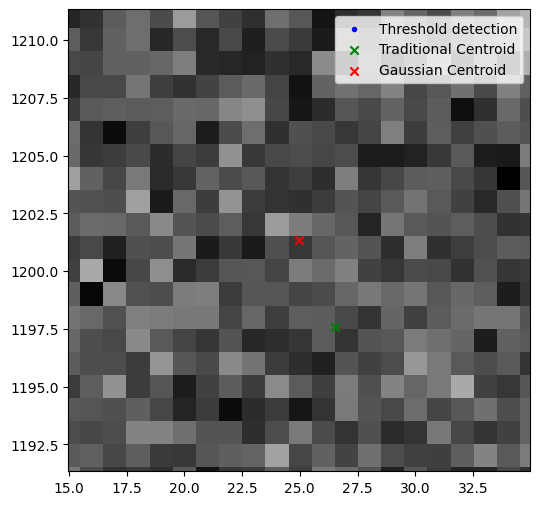

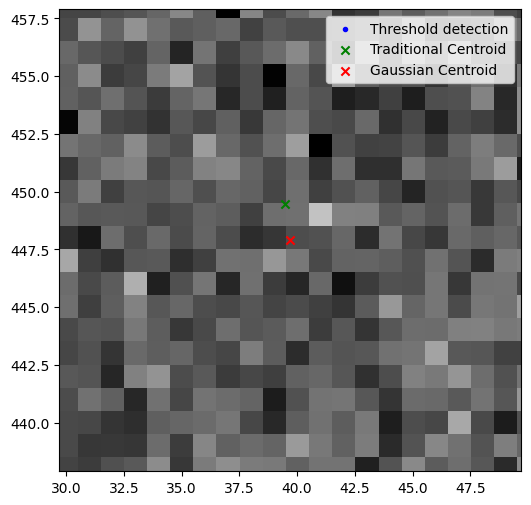

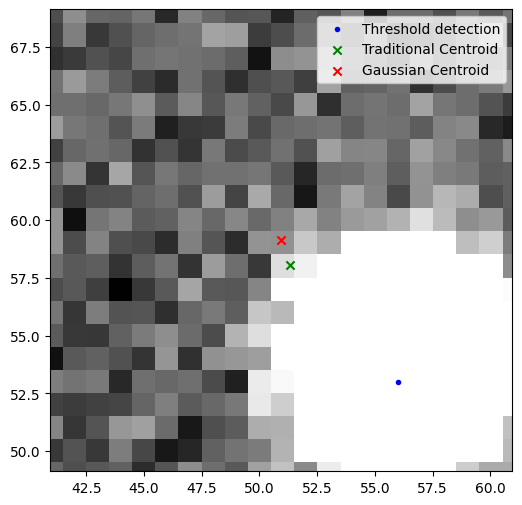

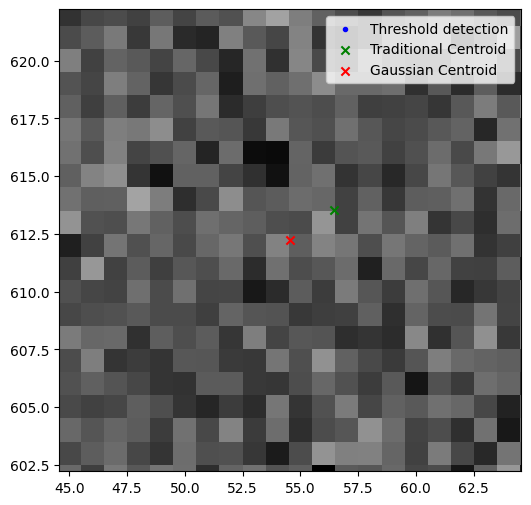

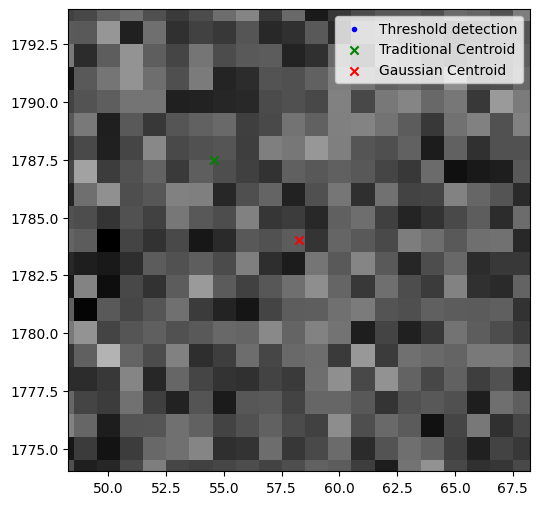

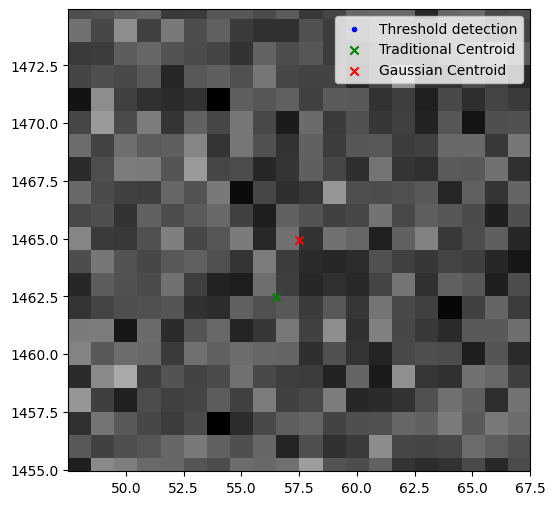

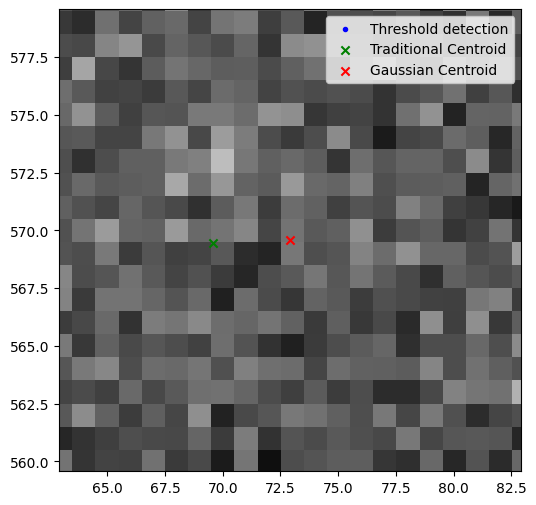

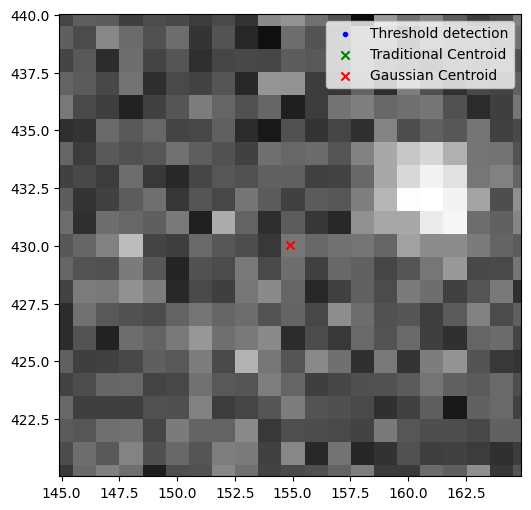

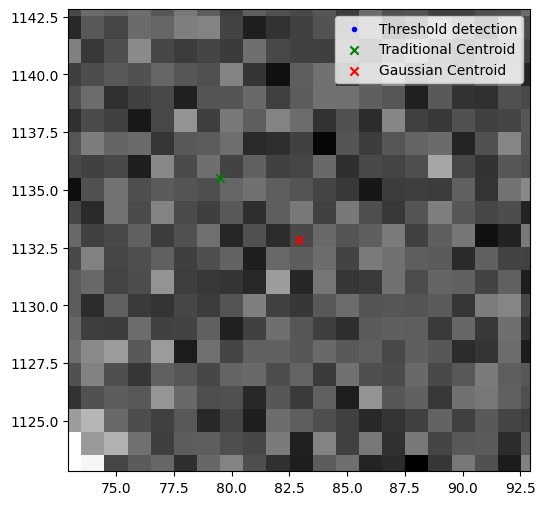

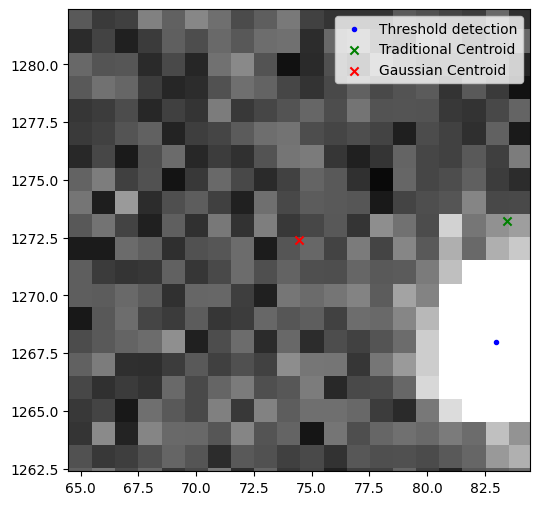

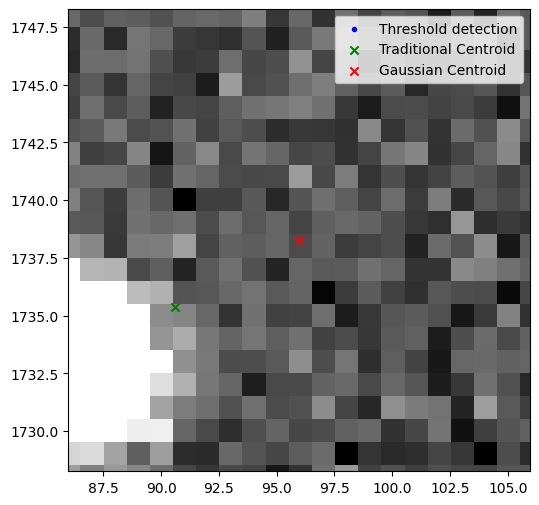

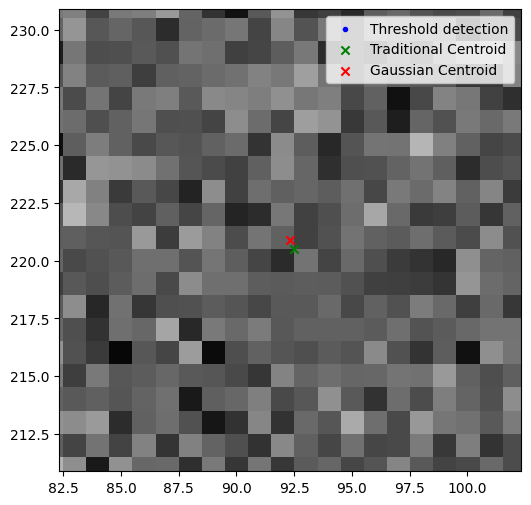

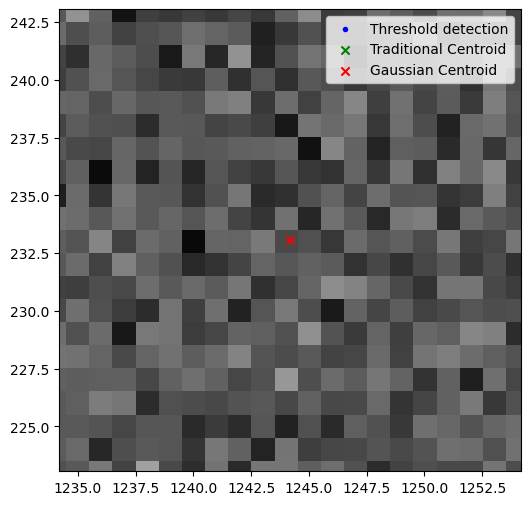

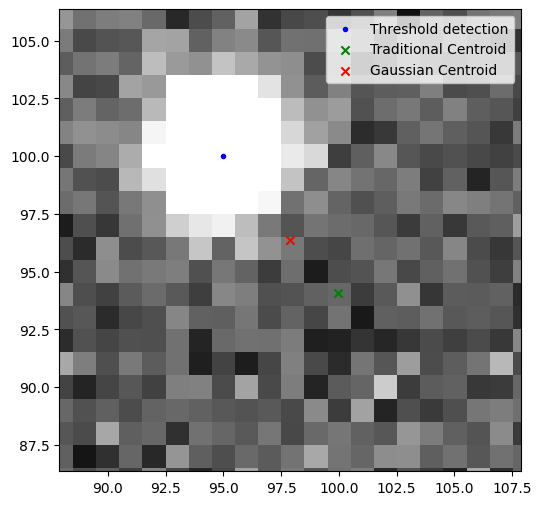

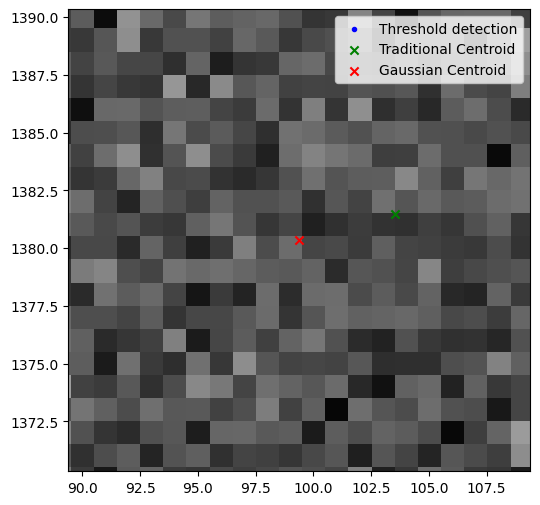

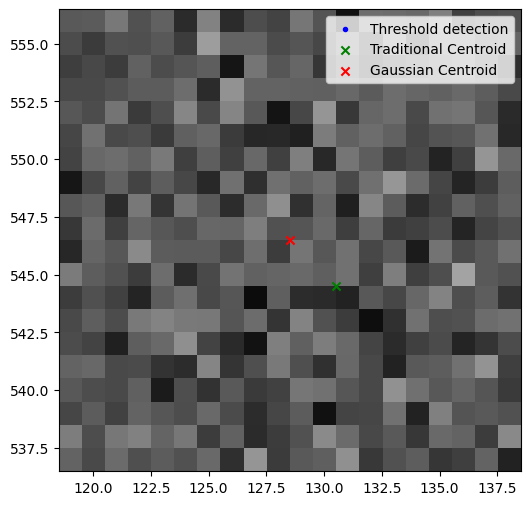

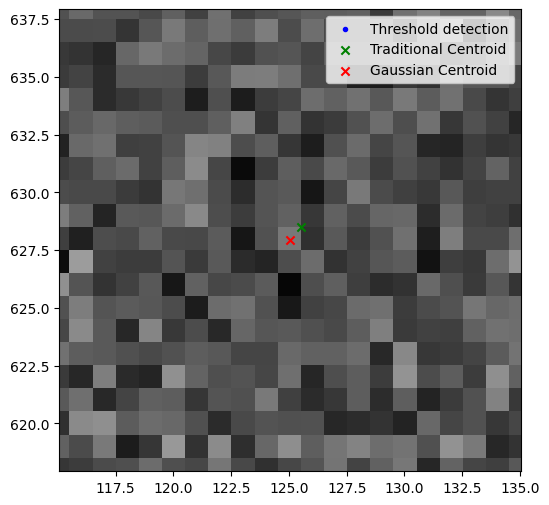

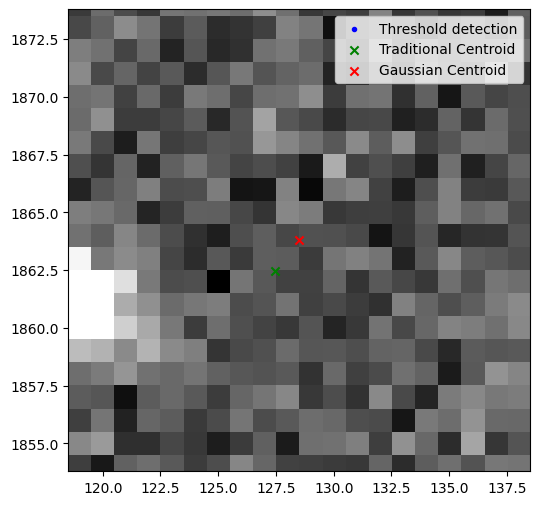

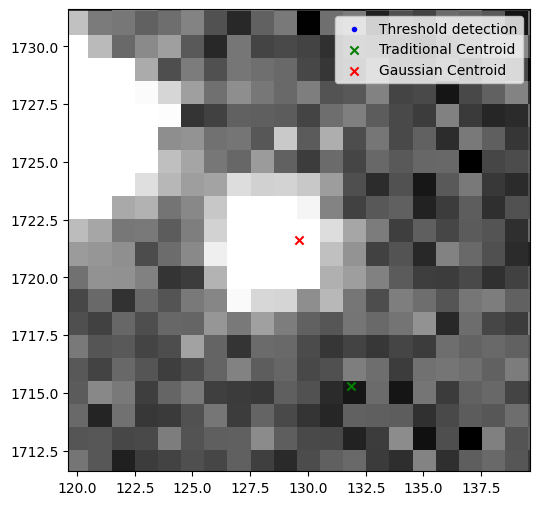

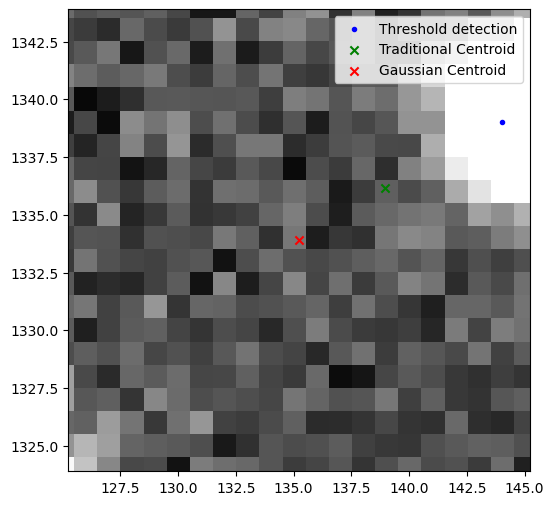

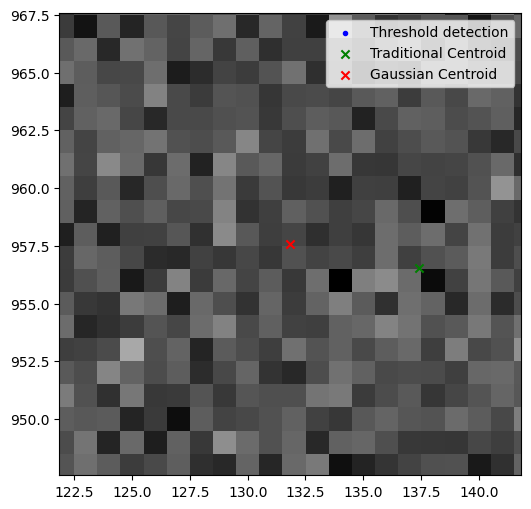

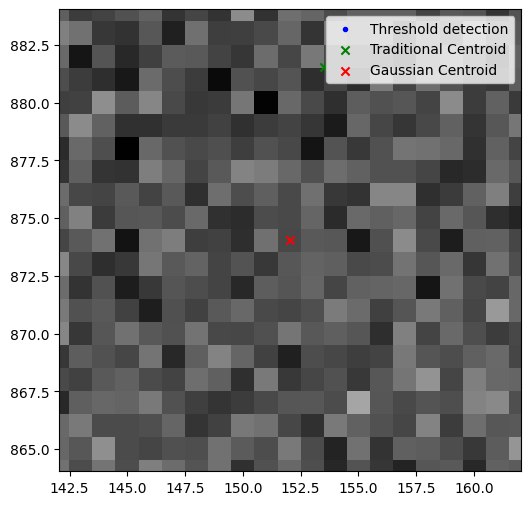

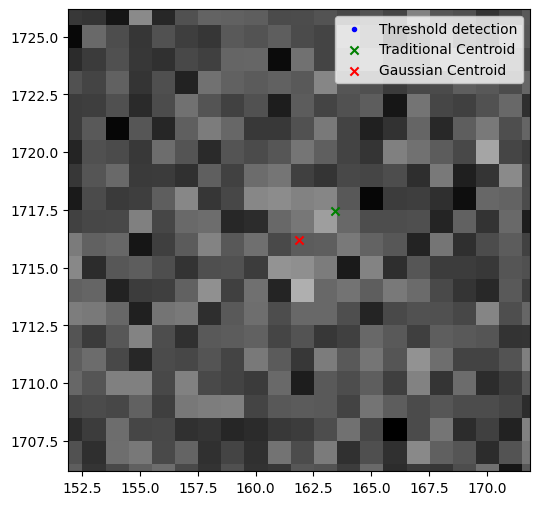

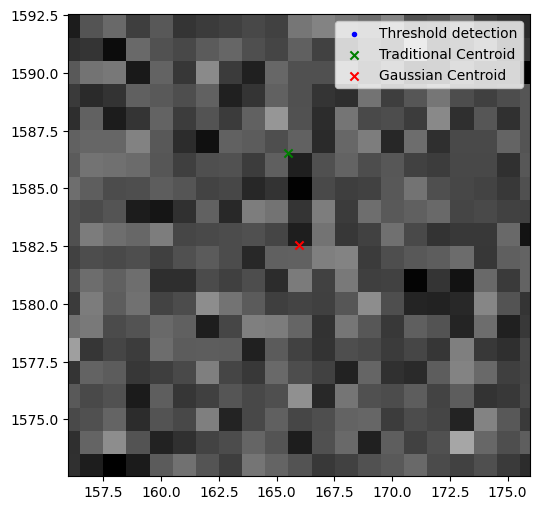

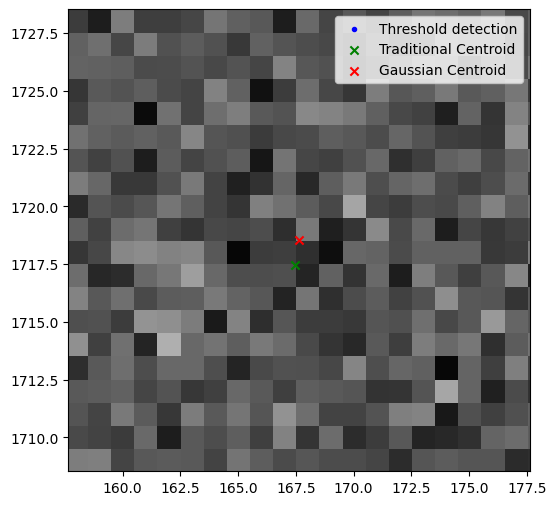

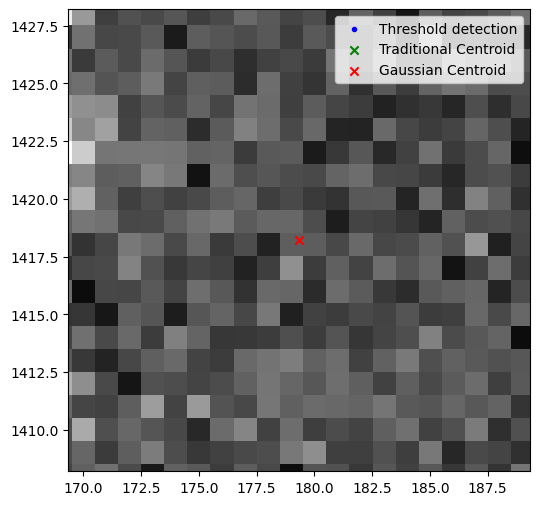

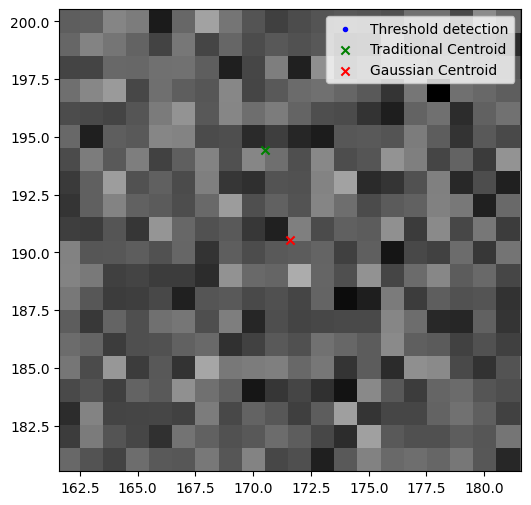

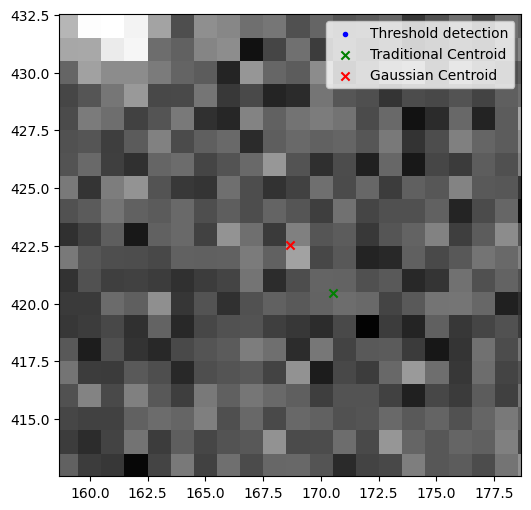

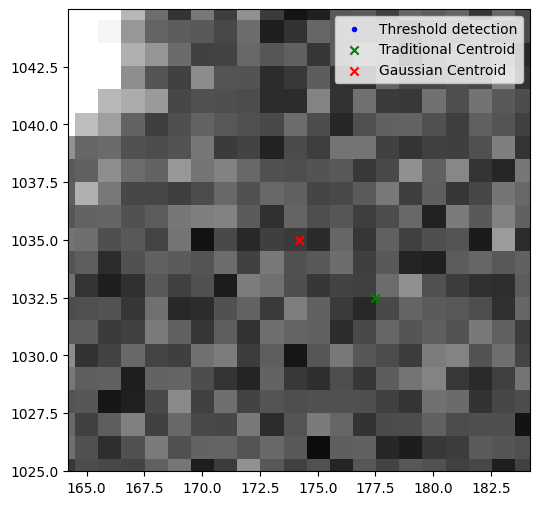

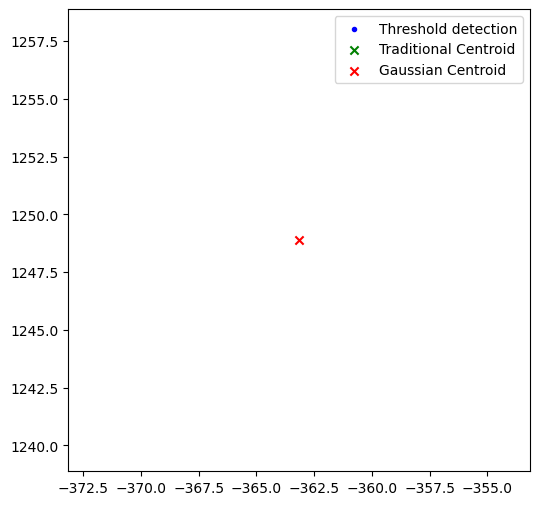

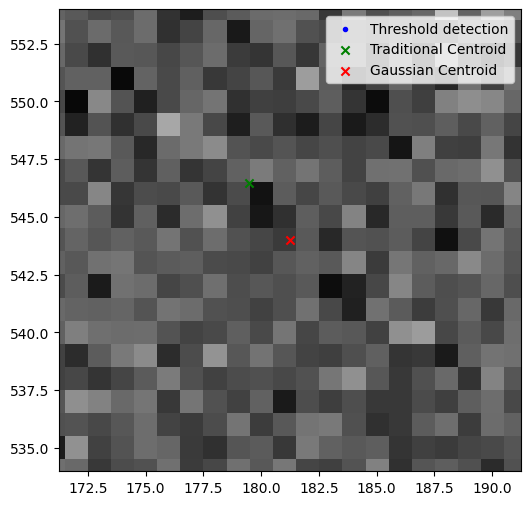

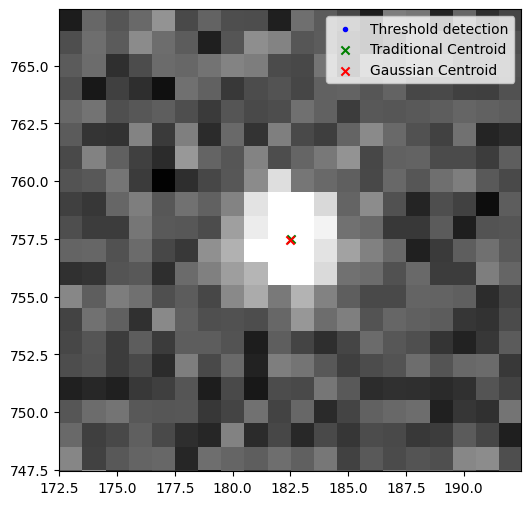

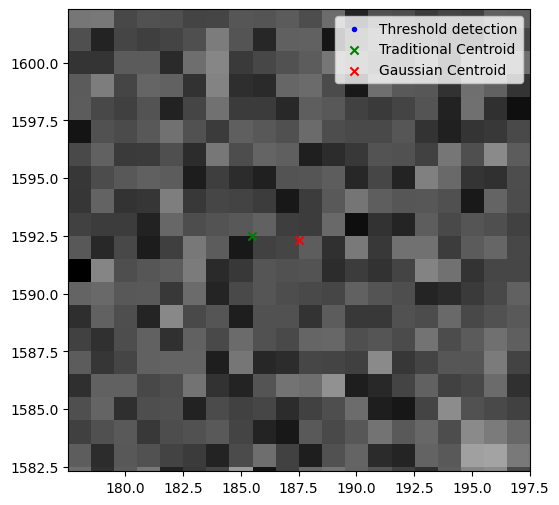

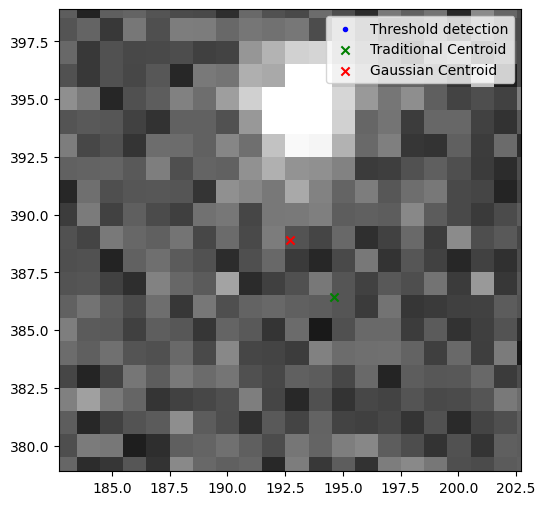

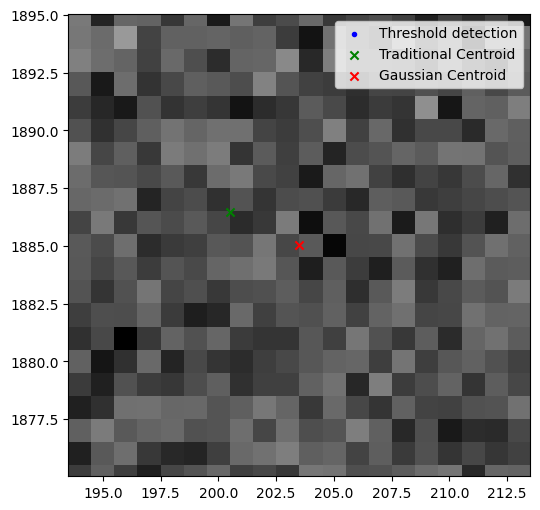

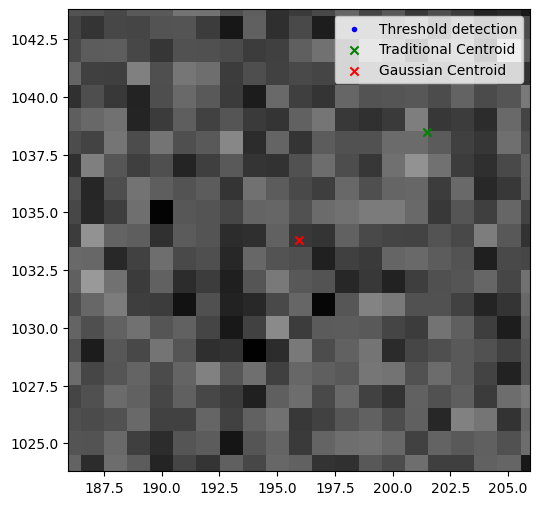

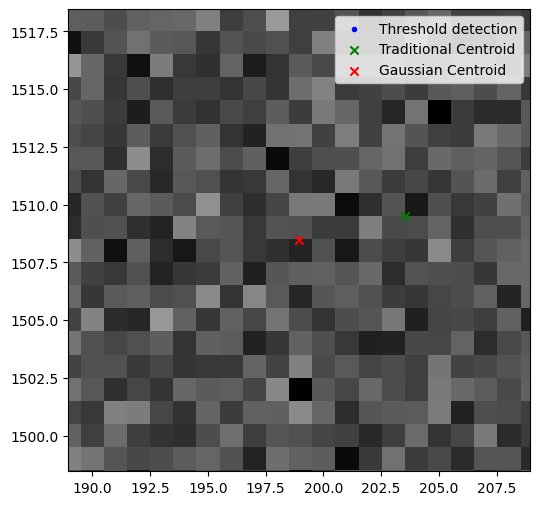

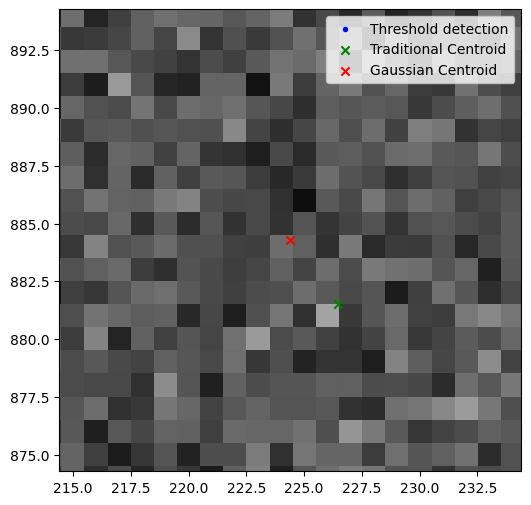

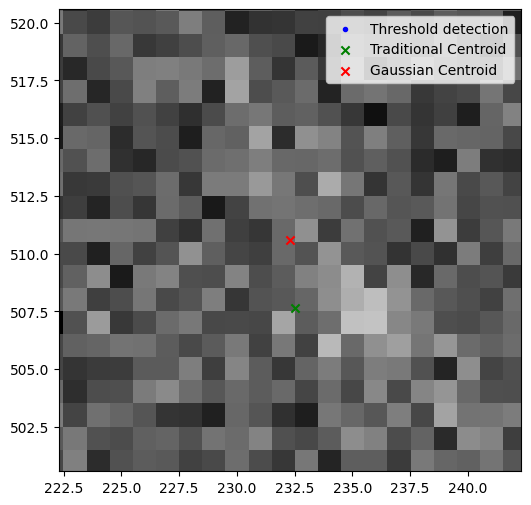

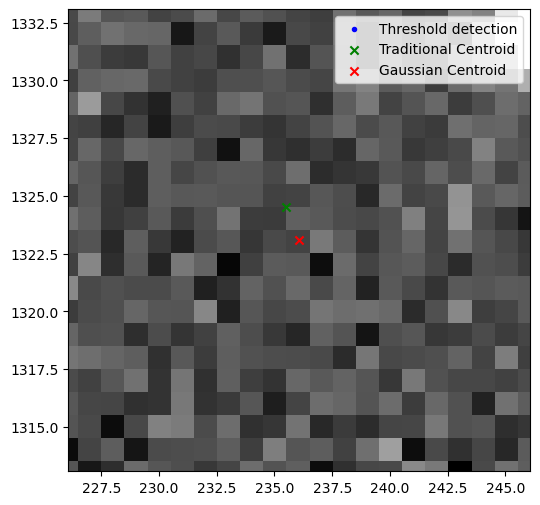

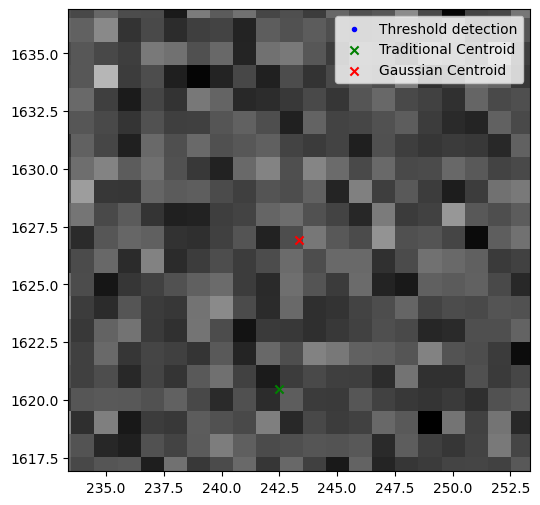

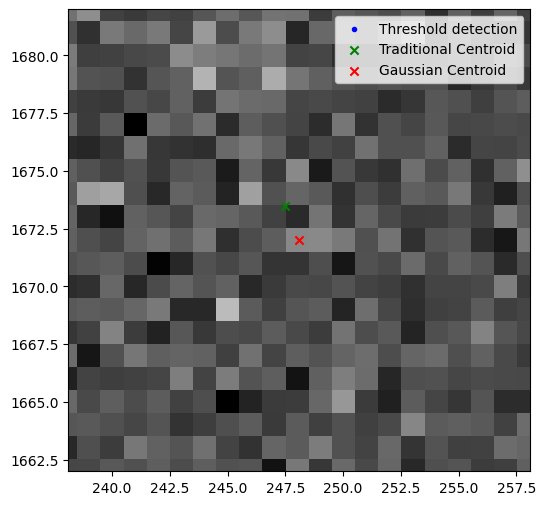

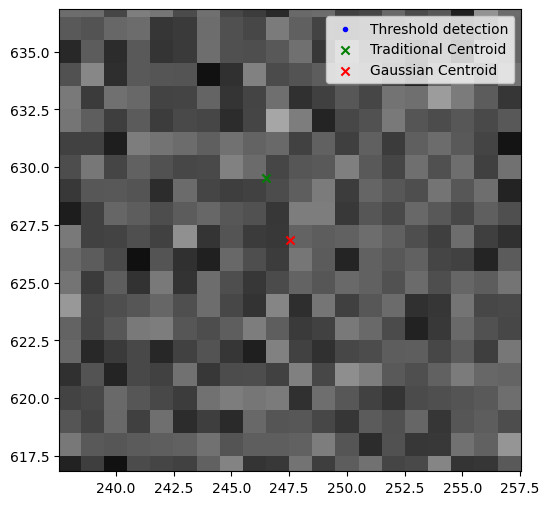

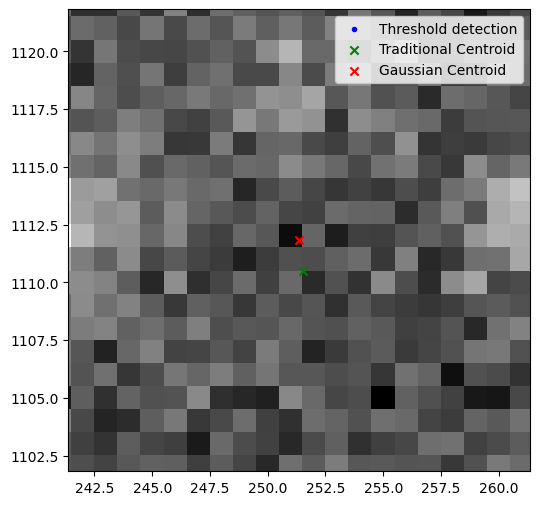

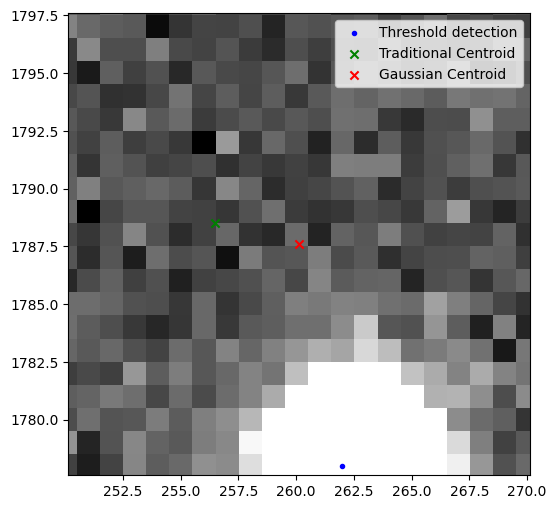

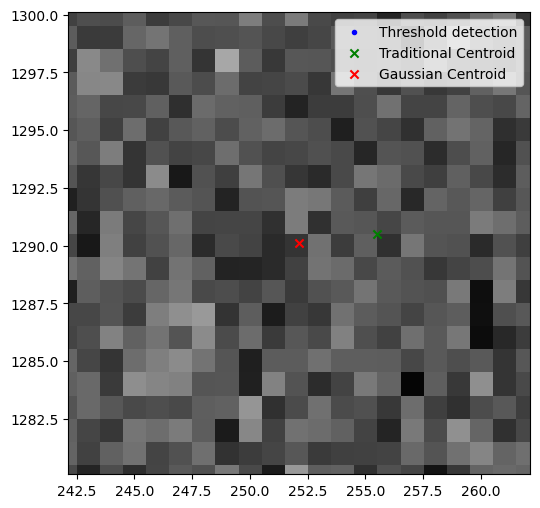

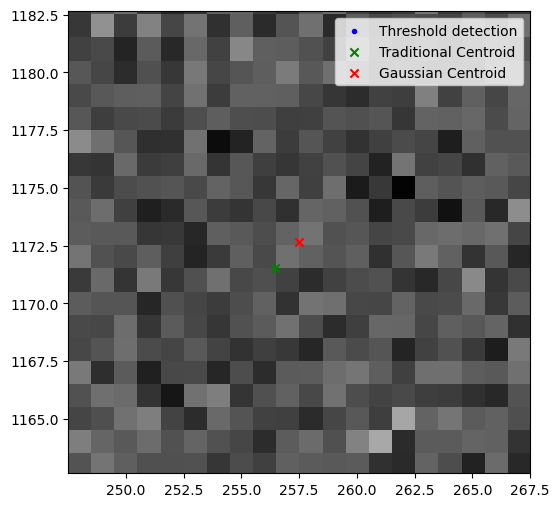

KeyboardInterrupt: 

In [78]:
threshold = 0.035
stars_x = []
stars_y = []
# Find parts of img where intensity > threshold
binary_img = np.where(science_imgs[0] > threshold, 1, 0)

# Assign each star region a different integer
star_labels, num_stars = label(binary_img)
print(f"Found {num_stars} stars")

# Loop through each region and pick a single point to feed the centroider.
for i in range(1,num_stars+1):
    region_coords = np.where(star_labels == i)
    # Use middle point in each region
    middle_x = np.mean(region_coords[0]).astype(int)
    middle_y = np.mean(region_coords[1]).astype(int) 
    stars_x.append(middle_y)
    stars_y.append(middle_x)
    
size=5
centroid_x, centroid_y, initial_cen_x, initial_cen_y = star_gaussian([stars_x, stars_y], science_imgs[0],threshold,size=size)
centroid_catalog = pd.DataFrame({'centroid_x': centroid_x, 'centroid_y': centroid_y})
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])

# View all centroids
for centroid in range(len(centroid_x)):
    fig = plt.figure(figsize=(12, 6))
    plt.imshow(science_imgs[0], vmin=vmin, vmax=vmax, origin='lower', cmap='gray')
    plt.scatter(stars_x,stars_y, marker='.', color='blue', label="Threshold detection", s=35)
    plt.scatter(initial_cen_x[centroid],initial_cen_y[centroid], marker='x', color='green', label="Traditional Centroid", s=35)
    plt.scatter(centroid_x[centroid],centroid_y[centroid], marker='x', color='red', label="Gaussian Centroid", s=35)
    plt.xlim(centroid_x[centroid]-size-5,centroid_x[centroid]+size+5)
    plt.ylim(centroid_y[centroid]-size-5,centroid_y[centroid]+size+5)
    plt.legend(loc='best')
    plt.show()
    


Getting USNO coordinates

Converting USNO RA/DEC positions into pixel coordinates

05h24m08.28107592s +26d58m30.98376984s


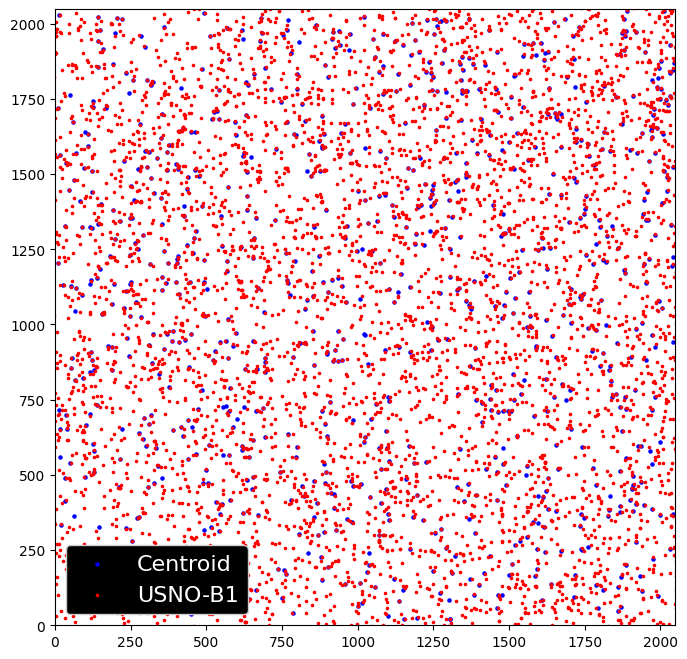

Num centroids 931
Num USNO 6671


In [ ]:
# Get center of field and query USNO-B1
cof = coord.SkyCoord(header(astroids[0])['CRVAL1'], header(astroids[0])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
print(cof.to_string('hmsdms'))
fov = 42*u.arcmin
Vizier.ROW_LIMIT = -1
usno = Vizier.query_region(cof, width=fov, catalog='USNO-B1')[0].to_pandas()

# plt.scatter(usno['RAJ2000'], usno['DEJ2000'], s=1, color='red')
# plt.xlabel('RA (deg)')
# plt.ylabel('Dec (deg)')
# plt.show()

mag_limit = 18.8
usno_reduced = usno[usno['R2mag'] < mag_limit].reset_index(drop=True)

# plt.scatter(usno_reduced['RAJ2000'], usno_reduced['DEJ2000'], s=2, color='red')
# plt.xlabel('RA (deg)')
# plt.ylabel('Dec (deg)')
# plt.show()

def initial_transform(usno_coords, focal_length, pixel_size, rotation, center_of_field, x_0, y_0):
    
    alpha = np.deg2rad(usno_coords[:,0])
    delta = np.deg2rad(usno_coords[:,1])
    alpha_0 = center_of_field.ra.rad
    delta_0 = center_of_field.dec.rad
    
    # Project to X and Y
    X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    
    x_offset = x_0
    y_offset = y_0
    
    # # Convert to pixels
    # x = focal_length*(X/pixel_size) + x_offset
    # y = focal_length*(Y/pixel_size) + y_offset
    
    x = (focal_length/pixel_size)*(X*np.cos(rotation) - Y*np.sin(rotation)) + x_offset
    y = (focal_length/pixel_size)*(X*np.sin(rotation) + Y*np.cos(rotation)) + y_offset
    return y,x

pixel_size = 0.01816 # mm
image_shape = (2048, 2048) # after binning
focal_length = 3454 # mm F/6.8
rotation = np.deg2rad(-88.9)
x_offset = 1024
y_offset = 1024
usno_stars = np.column_stack((usno_reduced['RAJ2000'], usno_reduced['DEJ2000']))

approximate_x, approximate_y = initial_transform(usno_stars, focal_length, pixel_size, rotation, cof, x_offset, y_offset)
usno_reduced['approx_x'] = approximate_x
usno_reduced['approx_y'] = approximate_y

fig = plt.figure(figsize=(8, 8))
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])
#plt.imshow(science_imgs[0], cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
plt.scatter(centroid_x, centroid_y, marker='.' , color ='blue', s=20, label='Centroid')
plt.scatter(usno_reduced['approx_x'], usno_reduced['approx_y'], marker='.', s=10, color='red', label='USNO-B1')
plt.xlim(0,2048)
plt.ylim(0,2048)
plt.legend(loc='lower left', fontsize = 16, labelcolor='white', facecolor='black', framealpha = 1)
plt.show()

print("Num centroids" , len(centroid_x))
print("Num USNO" , len(usno_reduced['approx_x']))


In [ ]:
# Returns nearest star 
def distance(centroid_catalog, catalog):    # Check distances between each centroid and all stars in catalog
    distances = cdist(centroid_catalog[['centroid_x', 'centroid_y']], catalog[['approx_x', 'approx_y']], metric='euclidean')
    nearest_star_indices = []
    nearest_star_distances = []
    # Find indexes of shortest distances for each centroid
    for i in range(len(distances)):
        nearest_star_indices.append(np.argmin(distances[i]))
        nearest_star_distances.append(np.min(distances[i]))
    return nearest_star_indices, nearest_star_distances

corresponding_usno, min_distance = distance(centroid_catalog, usno_reduced)
columns = ['USNO-B1.0','RAJ2000','DEJ2000','USNO_approx_x','USNO_approx_y','R2mag','pmRA','pmDE'] 
distance_threshold = 15
matched_stars = 0
total_centroids = len(centroid_catalog)
for i in range(len(centroid_catalog)):
    if min_distance[i] > distance_threshold:
        print(min_distance[i])
        usno_reduced.loc[corresponding_usno[i], 'separation'] = np.nan
        usno_reduced.loc[corresponding_usno[i], 'x_centroid'] = centroid_catalog['centroid_x'][i]
        usno_reduced.loc[corresponding_usno[i], 'y_centroid'] = centroid_catalog['centroid_y'][i]
    else:
        usno_reduced.loc[corresponding_usno[i], 'separation'] = min_distance[i]
        usno_reduced.loc[corresponding_usno[i], 'x_centroid'] = centroid_catalog['centroid_x'][i]
        usno_reduced.loc[corresponding_usno[i], 'y_centroid'] = centroid_catalog['centroid_y'][i]
        matched_stars += 1
print(f"Matched {matched_stars} out of {total_centroids} centroids")
usno_reduced = usno_reduced[['USNO-B1.0','RAJ2000','DEJ2000','approx_x','approx_y','x_centroid','y_centroid','separation','R2mag','pmRA','pmDE']]
usno_reduced = usno_reduced.dropna()

24.275656798333518
1799.2915473685198
13690.367532103512
22.260988507581782
30.527340925579924
15.225704012886562
8066.002701584827
17.550259544424936
37.51209426935135
161.7495900497113
32.62296810222937
12976.905520072036
25.72446161588479
17.433318098273617
16.605923320095947
3153.7464706336773
36.19670513834535
16.21930870023641
28.34884367509303
5781.208142722645
17.44769918374493
24.948464840588393
18.55996984966757
17.700120956812572
20.789619810011864
10788.545541190086
18.194689270861804
21.053936940457216
16.044540707119424
22.1445821997787
22.738382485784506
15.524530171204987
6533.698952597059
16209.415721300255
3075.464260537176
17.923197624242547
12236.734366182161
17.04116058920989
15492.186143925024
21.630583704177607
21.19274515978954
16.209217104723866
11780.956062338557
95.42041145060773
16.576091199073765
20.124664682037473
26.02803697542718
16.743856811648225
4216.5501147343475
33.14041508613558
29.39346357058227
18.123746951517514
16622.87754982031
Matched 878 out

Plate Solving

Need to find T

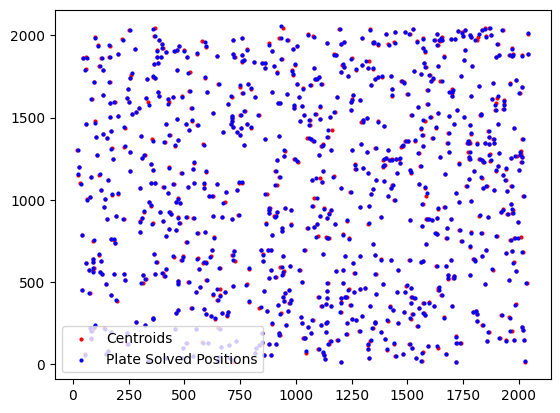

In [ ]:
alpha = np.deg2rad(usno_reduced['RAJ2000'])
delta = np.deg2rad(usno_reduced['DEJ2000'])
alpha_0 = cof.ra.rad
delta_0 = cof.dec.rad
X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))

# Solve for plate constants
f_p = focal_length/pixel_size
a_x = usno_reduced['x_centroid']
a_y = usno_reduced['y_centroid']
col1 = np.array(f_p*X)
col2 = np.array(f_p*Y)
col3 = np.ones_like(col1)
B = np.column_stack((col1, col2, col3))
c_x = np.linalg.lstsq(B, a_x, rcond=None)[0]
c_y = np.linalg.lstsq(B, a_y, rcond=None)[0]
T = np.array([[f_p*c_x[0], f_p*c_x[1], c_x[2]], [f_p*c_y[0], f_p*c_y[1], c_y[2]], [0, 0, 1]])

X_vec = np.array([X,Y,np.ones_like(X)])
x_lstsq = T[0][0]*X + T[0][1]*Y + T[0][2]
y_lstsq = T[1][0]*X + T[1][1]*Y + T[1][2]

usno_reduced['x_lstsq'] = x_lstsq
usno_reduced['y_lstsq'] = y_lstsq

plt.scatter(usno_reduced['y_centroid'], usno_reduced['x_centroid'], s=4, color='red', label='Centroids')
plt.scatter(usno_reduced['y_lstsq'], usno_reduced['x_lstsq'], s=4, color='blue', label='Plate Solved Positions')
plt.legend(loc='best')


In [ ]:
usno_reduced.to_csv('usno_reduced.csv', index=False)

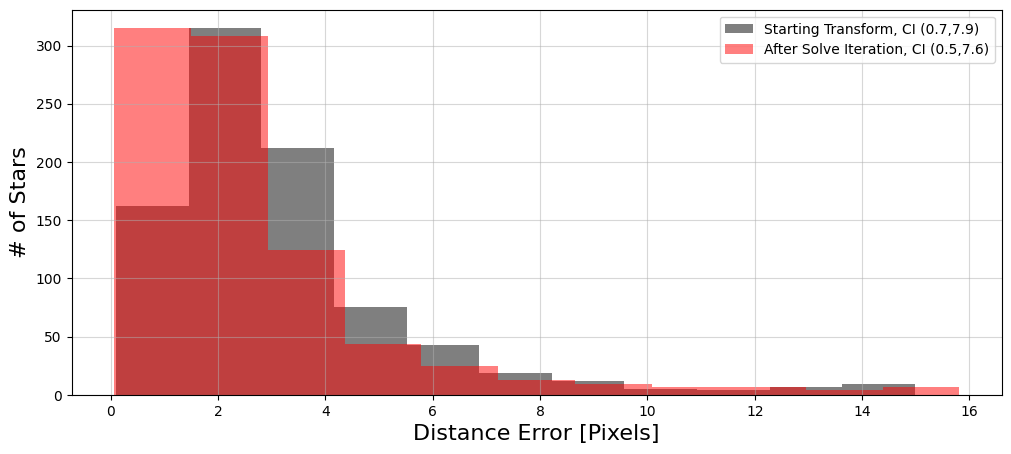

In [ ]:
usno_x_approx = np.array(usno_reduced['approx_x'])
usno_y_approx = np.array(usno_reduced['approx_y'])
ccd_x = np.array(usno_reduced['x_centroid'])
ccd_y = np.array(usno_reduced['y_centroid'])
usno_x = np.array(usno_reduced['x_lstsq'])
usno_y = np.array(usno_reduced['y_lstsq'])

def distance(x1,y1,x2,y2):
    return np.sqrt((x1-x2)**2+(y1-y2)**2)

min_dists_before = np.empty_like(usno_x)
min_dists_after = np.empty_like(usno_x)
usno_x_approx = np.array(usno_reduced['approx_x'])

for i in range(usno_x.size):
    min_dists_before[i] = np.min(distance(usno_x_approx[i], usno_y_approx[i], ccd_x, ccd_y))
    min_dists_after[i] = np.min(distance(usno_x[i], usno_y[i], ccd_x, ccd_y))

CI_b = (np.percentile(min_dists_before,5), 
      np.percentile(min_dists_before,95))
CI_a = (np.percentile(min_dists_after,5), 
      np.percentile(min_dists_after,95))

plt.figure(figsize=(12,5))
plt.hist(min_dists_before, 
         bins = "sturges", 
         color = 'k',
         alpha = 0.5, 
         label=f'Starting Transform, CI ({CI_b[0]:.1f},{CI_b[1]:.1f})')
plt.hist(min_dists_after, 
         bins = "sturges", 
         color = 'r',
         alpha = 0.5, 
         label =f'After Solve Iteration, CI ({CI_a[0]:.1f},{CI_a[1]:.1f})')
plt.grid(alpha=0.5)
plt.xlabel("Distance Error [Pixels]", size = 16)
plt.ylabel("# of Stars", size = 16)
plt.legend()
plt.show()

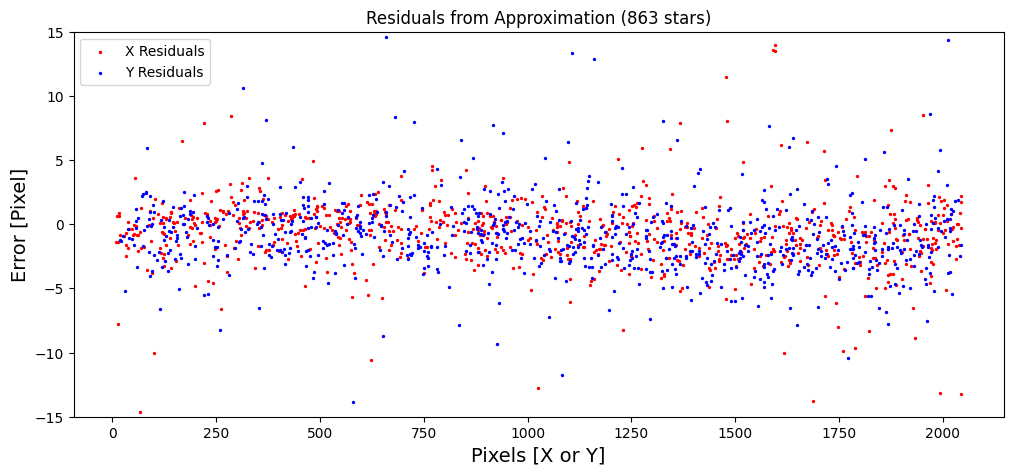

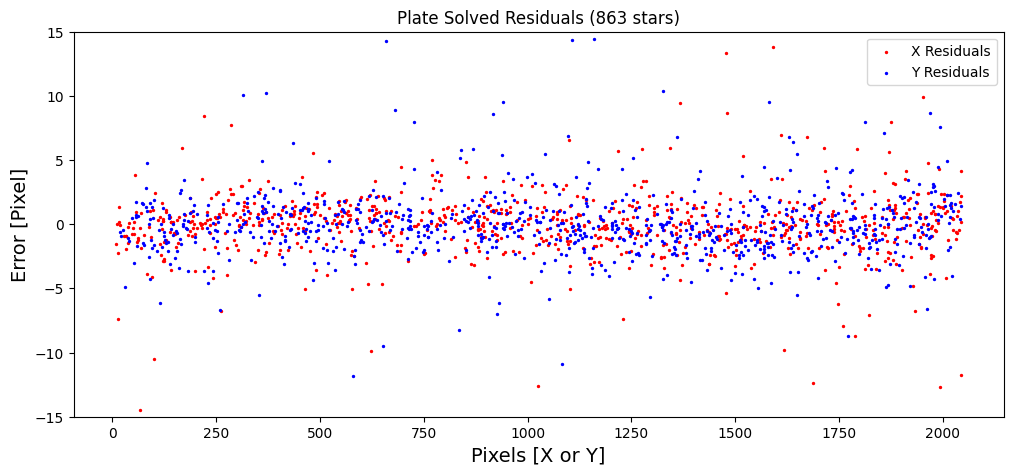

In [ ]:
# Plot residuals
plt.figure(figsize=(12,5))
plt.title(f"Residuals from Approximation ({len(usno_reduced)} stars)")
plt.xlabel("Pixels [X or Y]", fontsize=14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(usno_reduced['x_centroid'], usno_reduced['x_centroid'] - usno_reduced['approx_x'], s=2, color='red', label='X Residuals')
plt.scatter(usno_reduced['y_centroid'], usno_reduced['y_centroid'] - usno_reduced['approx_y'], s=2, color='blue', label='Y Residuals')
plt.legend(loc='best')
plt.ylim(-15,15)
plt.show()

plt.figure(figsize=(12,5))
plt.title(f"Plate Solved Residuals ({len(usno_reduced)} stars)")
plt.xlabel("Pixels [X or Y]", fontsize = 14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(usno_reduced['x_centroid'], usno_reduced['x_centroid'] - usno_reduced['x_lstsq'], s=2, color='red', label='X Residuals')
plt.scatter(usno_reduced['y_centroid'], usno_reduced['y_centroid'] - usno_reduced['y_lstsq'], s=2, color='blue', label='Y Residuals')
plt.ylim(-15,15)
plt.legend(loc='best')

# Add residuals to dataframe
usno_reduced['x_residual'] = usno_reduced['x_centroid'] - usno_reduced['x_lstsq']
usno_reduced['y_residual'] = usno_reduced['y_centroid'] - usno_reduced['y_lstsq']

# Filter final stars by x and y residuals
residual_threshold = 4 # pixels
final_stars = usno_reduced[(np.abs(usno_reduced['x_residual']) < residual_threshold) & (np.abs(usno_reduced['y_residual']) < residual_threshold)]

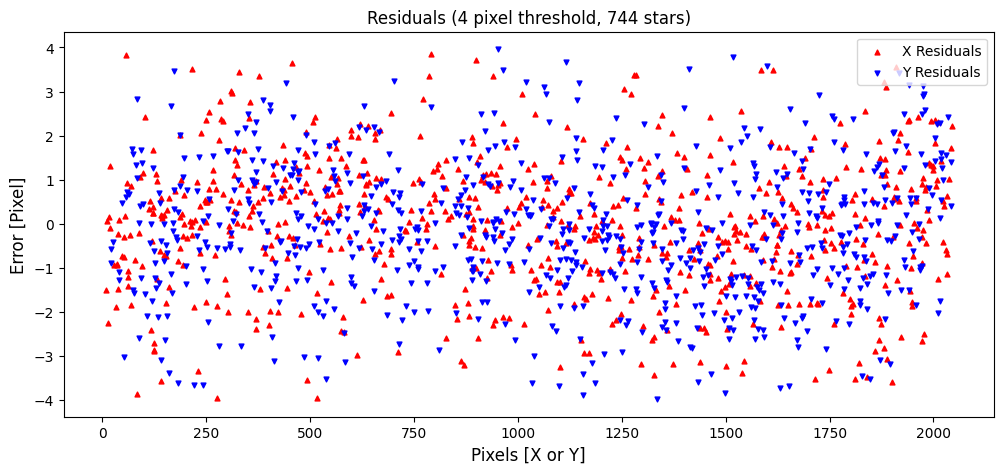

In [ ]:
# Plot final residuals
total_matched_stars = len(final_stars)
plt.figure(figsize=(12,5))
plt.title(f"Residuals ({residual_threshold} pixel threshold, {total_matched_stars} stars)".format(t=total_matched_stars))
plt.scatter(final_stars['x_centroid'], final_stars['x_residual'], s=12, color='red', label='X Residuals', marker = '^')
plt.scatter(final_stars['y_centroid'], final_stars['y_residual'], s=12, color='blue', label='Y Residuals', marker = 'v')
plt.xlabel("Pixels [X or Y]", fontsize = 12)
plt.ylabel("Error [Pixel]", fontsize = 12)
plt.legend(loc='best')
plt.grid('')
plt.show()

Now to deal with proserpina. First converting approximate locations from tutorial to pixel space.

In [ ]:
# alpha = np.deg2rad(usno_reduced['RAJ2000'])
# delta = np.deg2rad(usno_reduced['DEJ2000'])
# alpha_0 = cof.ra.rad
# delta_0 = cof.dec.rad
# X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
# Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))

# # Solve for plate constants
# a_x = usno_reduced['x_centroid']
# a_y = usno_reduced['y_centroid']
# col1 = np.array((focal_length/pixel_size)*X)
# col2 = np.array((focal_length/pixel_size)*Y)
# col3 = np.ones_like(col1)
# B = np.column_stack((col1, col2, col3))
# c_x = np.linalg.lstsq(B, a_x, rcond=None)[0]
# c_y = np.linalg.lstsq(B, a_y, rcond=None)[0]

# x_lstsq = c_x[0]*col1 +c_x[1]*col2 + c_x[2]
# y_lstsq = c_y[0]*col1 +c_y[1]*col2 + c_y[2]

def RADec_pixel(coordinate, center_field):
    alpha = coordinate.ra.rad
    delta = coordinate.dec.rad  
    alpha_0 = center_field.ra.rad
    delta_0 = center_field.dec.rad
    X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    y = T[0][0]*X + T[0][1]*Y + T[0][2]
    x = T[1][0]*X + T[1][1]*Y + T[1][2]
    return x, y

emphemeris = [("05 24 06.75", "26 58 48.3"), 
              ("05 23 33.06" ,"26 58 12.9"), 
              ("05 22 30.16", "26 58 38.4"), 
              ("05 21 14.29", "26 56 45.8")]

# emphemeris = [("05 24 06.75", "26 58 48.3"), 
#               ("05 23 33.06" ,"26 58 03.9"), 
#               ("05 22 30.16", "26 56 32.4"), 
#               ("05 21 14.29", "26 54 24.8")]

testcoord = coord.SkyCoord(80.834498, 26.949506, unit=(u.deg, u.deg), equinox='J2000')

coord1 = coord.SkyCoord(emphemeris[0][0], emphemeris[0][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord2 = coord.SkyCoord(emphemeris[1][0], emphemeris[1][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord3 = coord.SkyCoord(emphemeris[2][0], emphemeris[2][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord4 = coord.SkyCoord(emphemeris[3][0], emphemeris[3][1], unit=(u.hourangle, u.deg), equinox='J2000')

# Convert coordinates to pixel space
coord1_cof = coord.SkyCoord(header(astroids[0])['CRVAL1'], header(astroids[0])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
coord2_cof = coord.SkyCoord(header(astroids[3])['CRVAL1'], header(astroids[1])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
coord3_cof = coord.SkyCoord(header(astroids[6])['CRVAL1'], header(astroids[2])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')
coord4_cof = coord.SkyCoord(header(astroids[9])['CRVAL1'], header(astroids[3])['CRVAL2'], unit=(u.deg, u.deg), equinox='J2000')

coord1x, coord1y = RADec_pixel(coord1, coord1_cof)
coord2x, coord2y = RADec_pixel(coord2, coord2_cof)
coord3x, coord3y = RADec_pixel(coord3, coord3_cof)
coord4x, coord4y = RADec_pixel(coord4, coord4_cof)

# Day 1
d1t1 = header(asteroid1[0])['DATE-OBS']
d1t2 = header(asteroid1[1])['DATE-OBS']
d1t3 = header(asteroid1[2])['DATE-OBS']

# Day 2
d2t1 = header(asteroid2[0])['DATE-OBS']
d2t2 = header(asteroid2[1])['DATE-OBS']
d2t3 = header(asteroid2[2])['DATE-OBS']

# Day 3
d3t1 = header(asteroid3[0])['DATE-OBS']
d3t2 = header(asteroid3[1])['DATE-OBS']
d3t3 = header(asteroid3[2])['DATE-OBS']

# Day 4 
d4t1 = header(asteroid4[0])['DATE-OBS']
d4t2 = header(asteroid4[1])['DATE-OBS']
d4t3 = header(asteroid4[2])['DATE-OBS']

timestamps = [d1t1, d1t2, d1t3, d2t1, d2t2, d2t3, d3t1, d3t2, d3t3]
#print(timestamps)
#print(d1t1,d2t1,d3t1,d4t1)

Initial Coordinate: 1006.0486798836004, 1040.2414545593438
Inital Centroid: 1005.7385935002487, 1039.7460304724368
Gaussian Centroid: 1007.1235655035621, 1041.4684042975503
Couldn't fit 0 stars
Initial Coordinate: 1012.633852241542, 1005.9115965656654
Inital Centroid: 1017.3079287353733, 1000.475034078503
Gaussian Centroid: 1020.1366105016062, 997.7990588013125
Couldn't fit 0 stars
Initial Coordinate: 1017.1425846417818, 1029.7731120853255
Inital Centroid: 1009.4003447424305, 1037.141009476647
Gaussian Centroid: 1011.1636847919789, 1035.2558226927522
Couldn't fit 0 stars
Initial Coordinate: 412.3462949029365, 942.0260017979908
Inital Centroid: 411.820124042139, 941.3097374042777
Gaussian Centroid: 412.8850975151794, 925.9562568163664
Couldn't fit 0 stars
Day 1 RA DEC: (81.028125, 26.980083333333333)
Day 2 RA DEC: (80.88775, 26.97025)
Day 3 RA DEC: (80.62566666666665, 26.97733333333333)
Day 4 RA DEC: (80.30954166666665, 26.946055555555557)
Day 1 (Px): (1006.0486798836004, 1040.241454559

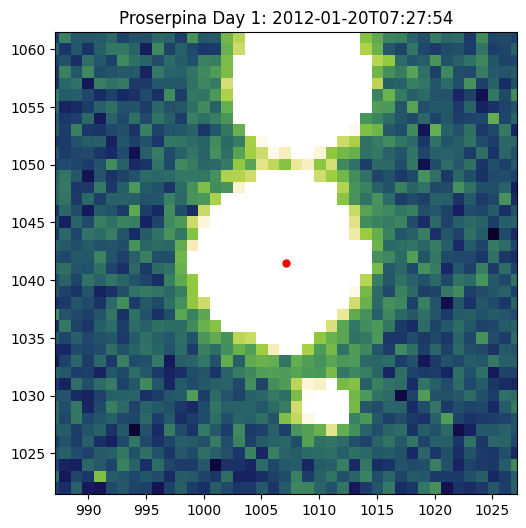

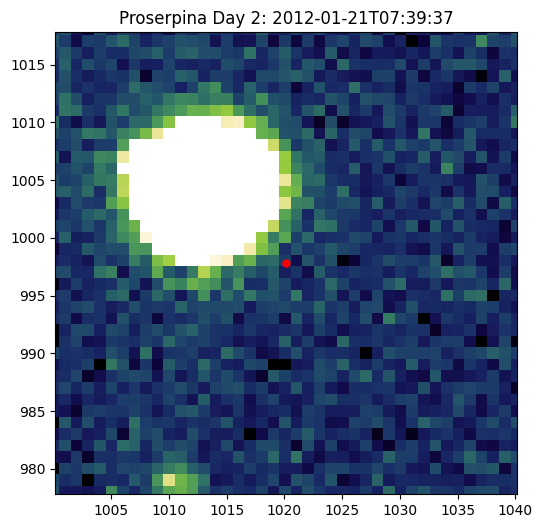

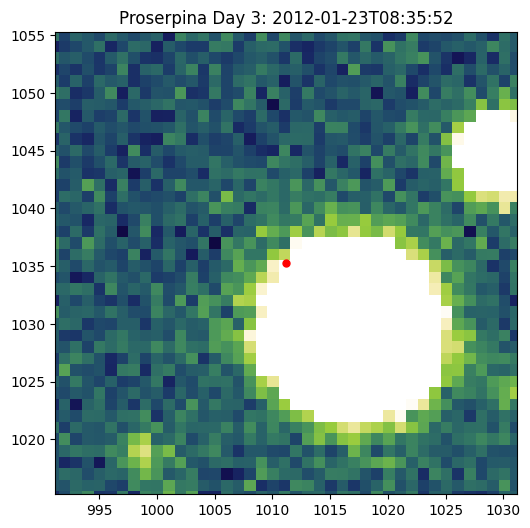

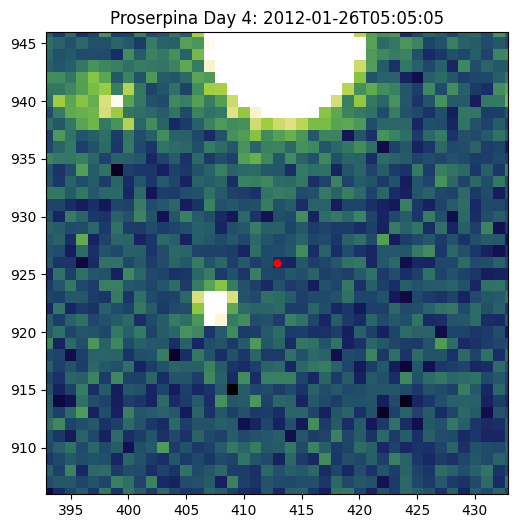

In [ ]:
# Centroiding proserpina
box = 20
d1_centroid = star_gaussian([[coord1x],[coord1y]], science_imgs[0], plot=True, size=box)
d2_centroid = star_gaussian([[coord2x],[coord2y]], science_imgs[3], plot=True, size=box)
d3_centroid = star_gaussian([[coord3x],[coord3y]], science_imgs[6], plot=True, size=box)
d4_centroid = star_gaussian([[coord4x],[coord4y]], science_imgs[9], plot=True, size=box)

x1, y1 = d1_centroid[0][0], d1_centroid[1][0]
x2, y2 = d2_centroid[0][0], d2_centroid[1][0]
x3, y3 = d3_centroid[0][0], d3_centroid[1][0]
x4, y4 = d4_centroid[0][0], d4_centroid[1][0]

# x1, y1 = coord1x, coord1y
# x2, y2 = coord2x, coord2y
# x3, y3 = coord3x, coord3y
# x4, y4 = coord4x, coord4y


print(f"Day 1 RA DEC: {coord1.ra.deg, coord1.dec.deg}")
print(f"Day 2 RA DEC: {coord2.ra.deg, coord2.dec.deg}")
print(f"Day 3 RA DEC: {coord3.ra.deg, coord3.dec.deg}")
print(f"Day 4 RA DEC: {coord4.ra.deg, coord4.dec.deg}")

print(f"Day 1 (Px): {coord1x, coord1y}")
print(f"Day 2 (Px): {coord2x, coord2y}")
print(f"Day 3 (Px): {coord3x, coord3y}")
print(f"Day 4 (Px): {coord4x, coord4y}")

print(f'Day 1 centroid: {x1, y1}')
print(f'Day 2 centroid: {x2, y2}')
print(f'Day 3 centroid: {x3, y3}')
print(f'Day 4 centroid: {x4, y4}')

vmin, max = ZScaleInterval().get_limits(science_imgs[0])

# Day 1 
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 1: {d1t1}")
plt.imshow(science_imgs[0], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x1, y1, marker='.', color='red', s=100, label='Centroid 1')
plt.xlim(x1-box, x1+box)
plt.ylim(y1-box, y1+box)
plt.show()

# Day 2
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 2: {d2t1}")
plt.imshow(science_imgs[3], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x2, y2, marker='.', color='red', s=100, label='Centroid 2')
plt.xlim(x2-box, x2+box)
plt.ylim(y2-box, y2+box)
plt.show()

# Day 3
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 3: {d3t1}")
plt.imshow(science_imgs[6], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x3, y3, marker='.', color='red', s=100, label='Centroid 3')
plt.xlim(x3-box, x3+box)
plt.ylim(y3-box, y3+box)
plt.show()

# Day 4
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 4: {d4t1}")
plt.imshow(science_imgs[9], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x4, y4, marker='.', color='red', s=100, label='Centroid 4')
plt.xlim(x4-box, x4+box)
plt.ylim(y4-box, y4+box)
plt.show()
